# Machine Learning: Exercise session 06

In this exercise session we will focus on Logistic regression and decision trees.

In the first problem, we will consider the [ionosphere dataset](https://www.openml.org/d/59) and fit different logistic regression models.
The goal is to predict whether a given radar signal from the ionosphere is "good" or "bad" based on 34 predictors.

In the second problem, we will focus on decision trees.

In the third problem, we will derive the log-likelihood function for logistic regression.

**Note:** the third problem is theoretical and __not__ needed for the hand in.

## Problem 1

* Import the dataset `ionosphere.csv`, separate the predictors and the target variable and split it into training and test set. When you perform the splitting, set `random_state=12` and `test_size=151`.

In [1]:
import pandas as pd

df = pd.read_csv("MLData/ionosphere.csv")
df.head()

# Split into features and target
X = df.drop("class", axis=1)
y = df["class"].map({"g": 1, "b": 0})  # Convert to binary labels

# split into training and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=151, random_state=12)

* Define a `Pipeline` where you apply the `StandardScaler` and then fit a `LogisticRegression` with the following tuning parameters: `penalty="none"`, `solver="saga"`, `tol=0.1`, `random_state=10`. Call the pipeline `pipe_logistic`.

In [12]:
def pipe_logistic():
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(solver = 'saga', tol = 0.1, random_state = 10, penalty = None))
    ])
    return pipe

* Fit the pipeline to the training data and predict the accuracy on the training and test dataset.

In [13]:
# Create pipeline
pipe_logistic = pipe_logistic()

# Fit pipeline
pipe_logistic.fit(X_train, y_train)

# Predict accuracy on training data
from sklearn.metrics import accuracy_score
y_pred_train = pipe_logistic.predict(X_train)
print("Logistic Regression --- Accuracy on training data:", accuracy_score(y_train, y_pred_train))

# Predict accuracy on test data
y_pred_test = pipe_logistic.predict(X_test)
print("Logistic Regression --- Accuracy on test data:", accuracy_score(y_test, y_pred_test))

Logistic Regression --- Accuracy on training data: 0.895
Logistic Regression --- Accuracy on test data: 0.8609271523178808


c:\Users\Guusd\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


We now want to fit a logistic regression with the lasso penalty. To do that we need to choose the best regulatization parameter. 

* Define a `Kfold` object with 10 splits, and `random_state=919`. Remeber to shuffle the rows. Name the object `folds`.

In [25]:
# Import
from sklearn.model_selection import KFold

# Instatiate folds with 10 splits, random 42
folds = KFold(n_splits=10, shuffle=True, random_state=919)

* Define a `Pipeline` where you first apply the `StandardScaler` (name this step `"scaler"`) and then fit a `LogisticRegression` (name this step `"logistic"`) with the following tuning parameters: `C=1`, `penalty="l1"`, `solver="saga"`, `tol=0.1`, `random_state=10`. Name the pipeline `pipe_logistic_l1`. What is the role of `C`? How does it compare to the tuning parameter `alpha` from `Lasso`?

In [29]:
def pipe_logistic_l1():
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(C = 1, solver = 'saga', tol = 0.1, random_state = 10, l1_ratio = 1))
    ])
    return pipe

# Create pipeline
pipe_logistic_l1 = pipe_logistic_l1()

# C is the inverse of regularization strength. Smaller values specify stronger regularization. We will use a range of C values to find the best one.

* Define now a `GridSearchCV` object to perform the cross-validation over a grid of different values for `C`. Fill in the `??`.

_Hint_: Choose carefully your grid, by trying out different possibility and looking at the cross-validated accuracy plot (see below). Ideally, you want a grid around the values of `C` that are "interesting".

In [34]:
import numpy as np
from sklearn.model_selection import GridSearchCV

# Define CV object
grid = 10 ** np.linspace(-4, 2, 100)
logistic_l1_cv = GridSearchCV(
    estimator=pipe_logistic_l1,
    param_grid={"logistic__C": grid},
    scoring="accuracy",
    cv=folds,
)

* Perform the cross-validation on the training data.

In [35]:
# Fit the model
logistic_l1_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...', tol=0.1))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'logistic__C': array([1.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the v

* Plot the results of the cross-validation by filling in the `??`.

_Note_: Notice that we want to compute the best model according to the __1-se rule__. To do that, we need to compute the standard error of the __mean__ cross-validated accuracy. This is obtained by dividing the standard deviations by the square root of $K = 10$ (i.e., number of folds).

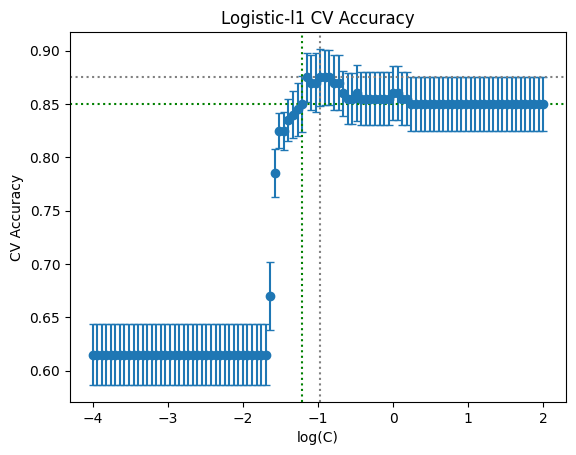

In [36]:
# Plot results of cross-validation
import matplotlib.pyplot as plt
cv_res = logistic_l1_cv

mean_scores = cv_res.cv_results_["mean_test_score"]
se_scores = cv_res.cv_results_["std_test_score"] / np.sqrt(10) # ! very important to divide by sqrt(# folds)
params = cv_res.cv_results_["param_logistic__C"].data

best_index = np.argmax(mean_scores)

one_se_best_param = np.min(
    grid[mean_scores >= mean_scores[best_index] - se_scores[best_index]]
)

one_se_score = mean_scores[grid == one_se_best_param][0]

# just for reference, we also plot the parameter that maximizes the cross-validated accuracy
best_param = cv_res.best_params_["logistic__C"] 
best_score = cv_res.best_score_

plt.errorbar(x=np.log10(grid), y=mean_scores, yerr=se_scores, fmt="o", capsize=3)

plt.axvline(
    np.log10(best_param), ls="dotted", color="grey"
)  # vertical line at the parameter value yielding highest accuracty
plt.axhline(
    best_score, ls="dotted", color="grey"
)  # horizontal line at highest accuracy
plt.axvline(
    np.log10(one_se_best_param), ls="dotted", color="green"
)  # vertical line at the parameter corresponding to 1-se
plt.axhline(
    one_se_score, ls="dotted", color="green"
)  # horizontal line at corresponding to 1-se parameter

plt.title("Logistic-l1 CV Accuracy")
plt.xlabel("log(C)")
plt.ylabel("CV Accuracy")
plt.show()

* Finally, refit the __1-se rule__ model to the whole training dataset, and compute the accuracy on the training and test dataset.

In [37]:
# Update pipeline with best parameter
pipe_logistic_l1.set_params(logistic__C=one_se_best_param)

# Fit pipeline again
pipe_logistic_l1.fit(X_train, y_train)

# Check accuracy on training and test data
train_accuracy = pipe_logistic_l1.score(X_train, y_train)
test_accuracy = pipe_logistic_l1.score(X_test, y_test)

print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Test accuracy:     {test_accuracy:.4f}")

Training accuracy: 0.8550
Test accuracy:     0.8278


* Does this model perform better than the unregularized logistic regression? What are the advantages of this model?

In [ ]:
# It performs a little worse by adding a penalty, but it is more robust to overfitting. It is simpler, making it easier to interpret and faster to run.

## Problem 2

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, train_test_split, GridSearchCV

### 2.0 Data import and Cleaning

Import the "Heart" dataset, containing demographic and medical informations about a list of patients. Drop `NA` values, convert the categorical variables into the desired pandas type: "category", and perform any other necessary data cleaning.

In [4]:
# Import dataset
heart = pd.read_csv("MLData/Heart_ISL.csv")

In [5]:
# Drop NAs
heart.dropna(inplace=True)  # Drop rows with missing values

# Convert catetorical variables into categorical type
heart['Thal'] = heart['Thal'].astype('category')
heart['ChestPain'] = heart['ChestPain'].astype('category')

The response variable that we will try to predict is "AHD", that indicates whether the patient has a heart disease.

Now split the data into the features `X` and the response `y`.

As, sadly, trees in sklearn do not handle categorical features directly, transform `X`'s categorical variables into "dummies". This can be achieved either with panda's `pd.get_dummies(<data>, drop_first=True)` or sklearn's `OneHotEncoder`. Make sure that you keep X in dataframe format, and keep feature/column names.

In [6]:
# Get X and y
X = heart.drop('AHD', axis=1)
y = heart['AHD'].map({'Yes': 1, 'No': 0})  # Convert to binary labels

# Transform categorical variables into dummy/indicator variables
X = pd.get_dummies(X, drop_first=True)  # Convert categorical variables to dummy

Split the data into train and test. Set random_state=40 and leave 20% of the data out for the test set.

In [7]:
# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=40)

### 2.1 Unpruned tree

In [1]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

Begin by fitting a (unpruned) classification tree to the training data, in order to predict whether each patient potentially has AHD, based on his available demographic and medical information. Use either the Gini index or the entropy as a splitting criterion, as you prefer.

In [8]:
# Create unpruned classification tree
UnTree = DecisionTreeClassifier(random_state=40)

# Fit tree
UnTree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",40
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

Now plot the tree using sklearn's `plot_tree` function

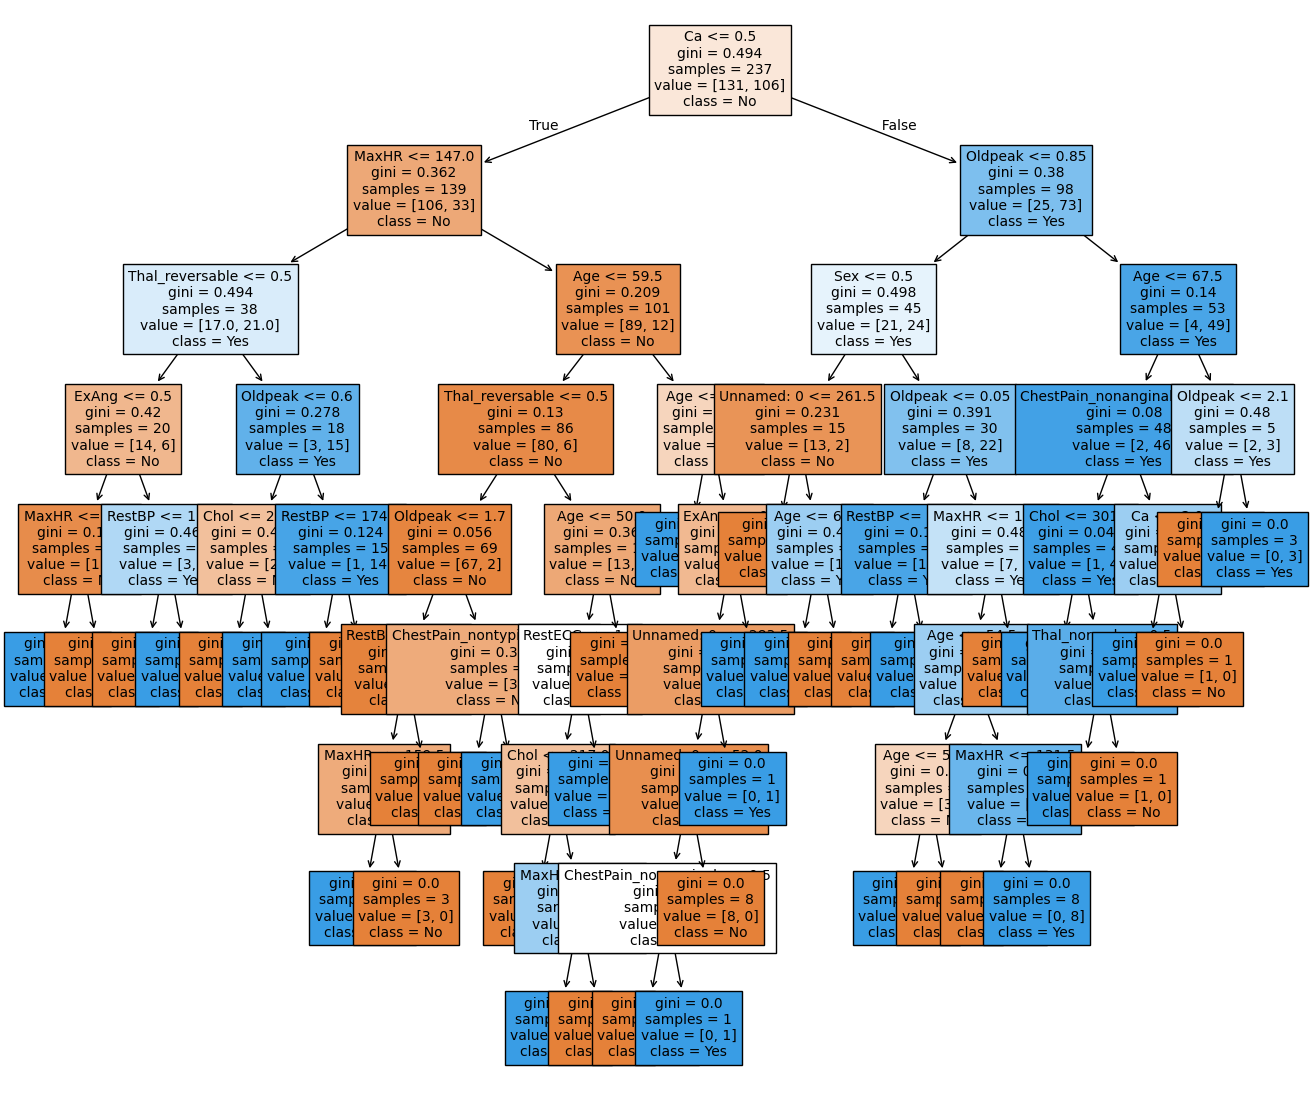

In [9]:
plt.figure(figsize=(16,14))
plot_tree(UnTree, filled=True, feature_names=X.columns, class_names=['No', 'Yes'], fontsize=10)
plt.show()

Could you use only this image to predict the "AHD" variable for the observations left out in the test set?

Now check the model's training and test accuracy (or score). What do you observe and why ?

In [10]:
print("Train accuracy:", UnTree.score(X_train, y_train))
print("Test accuracy:", UnTree.score(X_test, y_test))

# Perfect accuracy on train and way lower on test. Very overfitted. Tree is not interpretable with many specific nodes, showing overfitting again.

Train accuracy: 1.0
Test accuracy: 0.6666666666666666


### 2.2. Cost-complexity pruning

Remember that the flexibility of a decision tree can be tuned by pruning it via cost-complexity pruning.

Use cross-validation to select the best cost-complexity hyper-parameter $\alpha$ value. Then, plot the tree coresponding to the best $\alpha$ value.

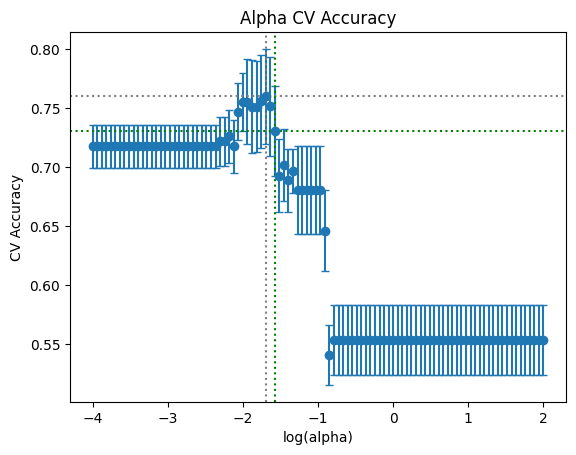

In [17]:
# Create cross-validation folds
folds = KFold(n_splits=10, shuffle=True, random_state=40)

import numpy as np
from sklearn.model_selection import GridSearchCV

# Define CV object
grid = 10 ** np.linspace(-4, 2, 100)
Tree_cv = GridSearchCV(
    estimator=UnTree,
    param_grid={"ccp_alpha": grid},
    scoring="accuracy",
    cv=folds,
)

# Fit the model
Tree_cv.fit(X_train, y_train)

# Plot results of cross-validation
import matplotlib.pyplot as plt
cv_res = Tree_cv

mean_scores = cv_res.cv_results_["mean_test_score"]
se_scores = cv_res.cv_results_["std_test_score"] / np.sqrt(10) # ! very important to divide by sqrt(# folds)
params = cv_res.cv_results_["param_ccp_alpha"].data

best_index = np.argmax(mean_scores)

one_se_best_param = np.max(
    grid[mean_scores >= mean_scores[best_index] - se_scores[best_index]]
)

one_se_score = mean_scores[grid == one_se_best_param][0]

# just for reference, we also plot the parameter that maximizes the cross-validated accuracy
best_param = cv_res.best_params_["ccp_alpha"] 
best_score = cv_res.best_score_

plt.errorbar(x=np.log10(grid), y=mean_scores, yerr=se_scores, fmt="o", capsize=3)

plt.axvline(
    np.log10(best_param), ls="dotted", color="grey"
)  # vertical line at the parameter value yielding highest accuracty
plt.axhline(
    best_score, ls="dotted", color="grey"
)  # horizontal line at highest accuracy
plt.axvline(
    np.log10(one_se_best_param), ls="dotted", color="green"
)  # vertical line at the parameter corresponding to 1-se
plt.axhline(
    one_se_score, ls="dotted", color="green"
)  # horizontal line at corresponding to 1-se parameter

plt.title("Alpha CV Accuracy")
plt.xlabel("log(alpha)")
plt.ylabel("CV Accuracy")
plt.show()


In [ ]:
# Fit tree with best parameter
best_tree = DecisionTreeClassifier(ccp_alpha=best_param)
best_tree.fit(X_train, y_train)

# Check accuracy on training and test data
train_accuracy = best_tree.score(X_train, y_train)
test_accuracy = best_tree.score(X_test, y_test)

print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Test accuracy:     {test_accuracy:.4f}")

Training accuracy: 0.8523
Test accuracy:     0.7500


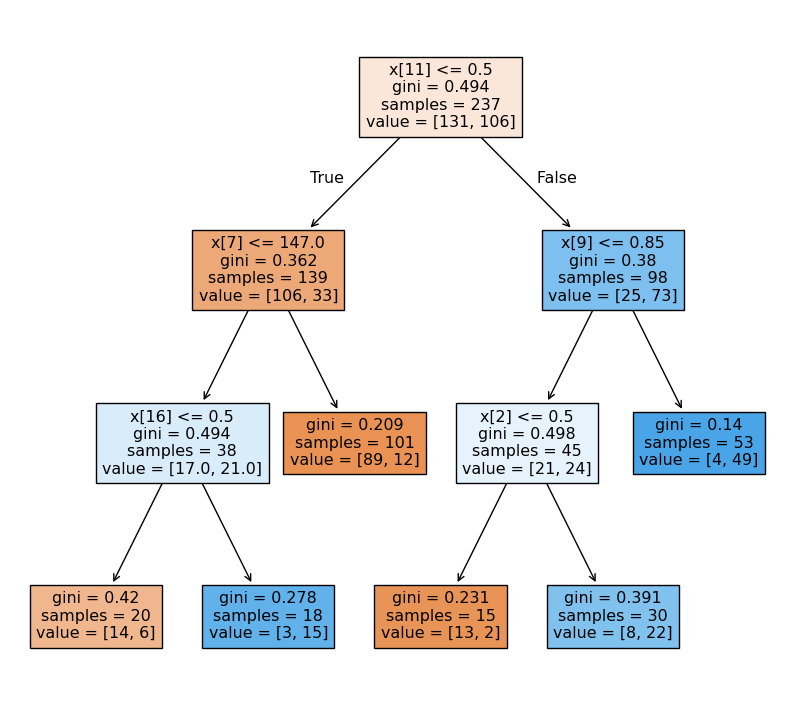

In [ ]:
# Show the tree with the best parameter
plt.figure(figsize=(10,9))
plot_tree(best_tree, filled=True)
plt.show()

# Way easier tree leads to lower training accuracy (85% vs 100%), but higher test accuracy (75% vs 66,6%). Less overfitting leads to better generalization.

## Problem 3 (not to hand in)

Suppose we have independent observations $(x_1,y_1),\dots, (x_n,y_n)$ from $(X,Y)$ with $x_i \in \mathbb R^p$, and $y_i \in \{0,1\}$,  $i = 1, \dots, n$.
Further assume that the conditional distribution of $Y$ given $X= x$ is Bernoulli with success probability denoted as:
  $$ \mathbb P(Y = 1 \mid X = x) = 1 - \mathbb P(Y = 0 \mid X = x) = \sigma(x^\top \beta),$$
where $\sigma: \mathbb R \to [0, 1]$, and
  $$
  \sigma(a) = \dfrac{e^{a}}{1 + e^{a}}, \quad a\in \mathbb R.
$$
Show that the log-likelihood of the parameter vector $\beta\in\mathbb R^p$ is
  $$\ell(\beta) = \sum_{i=1}^n y_i x_i^\top \beta - \log(1 + e^{x_i^\top \beta}).$$